### Feature (X) and Target (y) setup

In [130]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import sqlite3
import xgboost as xgb
from xgboost import XGBClassifier

#### Goal:
- To predict whether a team will win or lose depending on the box score of their team on that specific game

In [131]:
conn = sqlite3.connect("boxscore_ai.db")
df = pd.read_sql("SELECT * FROM games", conn)
conn.close
df.head()

,GAME_ID,TEAM_ID,SEASON_ID,GAME_DATE,TEAM_ABBREVIATION,MATCHUP,WL,PTS,AST,STL,...,FGM,FGA,FG_PCT,FG3M,FG3A,FTM,FTA,OREB,DREB,REB
0,22400062,1610612750,22024,2024-10-22,MIN,MIN @ LAL,L,103,17,4,...,35,85,0.412,13,41,20,27,12,35,47
1,22400062,1610612747,22024,2024-10-22,LAL,LAL vs. MIN,W,110,22,7,...,42,95,0.442,5,30,21,25,15,31,46
2,22400061,1610612738,22024,2024-10-22,BOS,BOS vs. NYK,W,132,33,6,...,48,95,0.505,29,61,7,8,11,29,40
3,22400061,1610612752,22024,2024-10-22,NYK,NYK @ BOS,L,109,20,2,...,43,78,0.551,11,30,12,16,5,29,34
4,22400065,1610612753,22024,2024-10-23,ORL,ORL @ MIA,W,116,28,8,...,41,96,0.427,18,49,16,22,18,39,57


In [132]:
# summary statistics for whole season stats
df.describe().round(2)

,GAME_ID,TEAM_ID,SEASON_ID,PTS,AST,STL,BLK,TOV,FGM,FGA,FG_PCT,FG3M,FG3A,FTM,FTA,OREB,DREB,REB
count,2460.00,2.460000e+03,2460.0,2460.00,2460.00,2460.00,2460.00,2460.00,2460.00,2460.00,2460.00,2460.00,2460.00,2460.00,2460.00,2460.00,2460.00,2460.00
mean,22400615.50,1.610613e+09,22024.0,113.83,26.55,8.20,4.88,14.30,41.69,89.24,0.47,13.54,37.58,16.90,21.67,11.12,32.99,44.11
std,355.14,8.660000e+00,0.0,12.71,5.29,3.09,2.46,4.03,5.27,7.29,0.05,3.95,7.03,5.72,6.88,3.95,5.42,6.73
min,22400001.00,1.610613e+09,22024.0,67.00,9.00,1.00,0.00,3.00,22.00,67.00,0.29,3.00,12.00,3.00,3.00,1.00,16.00,23.00
25%,22400308.00,1.610613e+09,22024.0,105.00,23.00,6.00,3.00,11.00,38.00,84.00,0.43,11.00,33.00,13.00,17.00,8.00,29.00,39.00
50%,22400615.50,1.610613e+09,22024.0,114.00,26.00,8.00,5.00,14.00,42.00,89.00,0.47,13.00,37.00,16.00,21.00,11.00,33.00,44.00
75%,22400923.00,1.610613e+09,22024.0,122.00,30.00,10.00,6.00,17.00,45.00,94.00,0.51,16.00,42.00,21.00,26.00,14.00,37.00,48.00
max,22401230.00,1.610613e+09,22024.0,162.00,48.00,22.00,18.00,31.00,60.00,119.00,0.69,29.00,63.00,43.00,53.00,28.00,52.00,73.00


In [133]:
# created a copy so we don't modify the original data which is the best practice
df_copy = df.copy()
df_copy.head()

,GAME_ID,TEAM_ID,SEASON_ID,GAME_DATE,TEAM_ABBREVIATION,MATCHUP,WL,PTS,AST,STL,...,FGM,FGA,FG_PCT,FG3M,FG3A,FTM,FTA,OREB,DREB,REB
0,22400062,1610612750,22024,2024-10-22,MIN,MIN @ LAL,L,103,17,4,...,35,85,0.412,13,41,20,27,12,35,47
1,22400062,1610612747,22024,2024-10-22,LAL,LAL vs. MIN,W,110,22,7,...,42,95,0.442,5,30,21,25,15,31,46
2,22400061,1610612738,22024,2024-10-22,BOS,BOS vs. NYK,W,132,33,6,...,48,95,0.505,29,61,7,8,11,29,40
3,22400061,1610612752,22024,2024-10-22,NYK,NYK @ BOS,L,109,20,2,...,43,78,0.551,11,30,12,16,5,29,34
4,22400065,1610612753,22024,2024-10-23,ORL,ORL @ MIA,W,116,28,8,...,41,96,0.427,18,49,16,22,18,39,57


In [134]:
print(df_copy.groupby("TEAM_ID").size())

TEAM_ID
1610612737    82
1610612738    82
1610612739    82
1610612740    82
1610612741    82
1610612742    82
1610612743    82
1610612744    82
1610612745    82
1610612746    82
1610612747    82
1610612748    82
1610612749    82
1610612750    82
1610612751    82
1610612752    82
1610612753    82
1610612754    82
1610612755    82
1610612756    82
1610612757    82
1610612758    82
1610612759    82
1610612760    82
1610612761    82
1610612762    82
1610612763    82
1610612764    82
1610612765    82
1610612766    82
dtype: int64


In [135]:
# basis of train/test split through a cut off date
df_copy = df_copy.sort_values(by=["GAME_DATE"]) # default ascending


In [ ]:
stats = ["PTS", "FG_PCT", "AST", "REB"]

# models will predict the outcome of the game based on the previous 5 games before that game 
# NOTE: if current game = N, the ouput rows are N-5 through n-1, the N game it self is excluded to prevent models from looking at the answer  
for col in stats:
    df_copy[f"{col}_last_5_games_avg"] = (
        df_copy.groupby("TEAM_ID")[col]
        .transform(lambda x: 
            x.shift(1)
            .rolling(5)
            .mean()     
        )
    )

# df_copy.head() # first 5 values will be none because it was shifted
df_copy.tail()

,GAME_ID,TEAM_ID,SEASON_ID,GAME_DATE,TEAM_ABBREVIATION,MATCHUP,WL,PTS,AST,STL,...,FG3A,FTM,FTA,OREB,DREB,REB,PTS_last_5_games_avg,FG_PCT_last_5_games_avg,AST_last_5_games_avg,REB_last_5_games_avg
134,22400128,1610612763,22024,2024-10-31,MEM,MEM vs. MIL,W,122,26,6,...,28,28,31,7,49,56,NaN,NaN,NaN,NaN
152,22400133,1610612753,22024,2024-11-01,ORL,ORL @ CLE,L,109,26,10,...,33,16,24,7,32,39,NaN,NaN,NaN,NaN
159,22400132,1610612738,22024,2024-11-01,BOS,BOS @ CHA,W,124,21,12,...,42,29,35,11,30,41,NaN,NaN,NaN,NaN
157,22400137,1610612747,22024,2024-11-01,LAL,LAL @ TOR,W,131,29,6,...,32,36,41,9,34,43,NaN,NaN,NaN,NaN
156,22400140,1610612757,22024,2024-11-01,POR,POR vs. OKC,L,114,27,8,...,35,21,31,11,25,36,NaN,NaN,NaN,NaN


In [ ]:
#  since first 5 values are NaN, we start from row 6 onwards
df_copy = df_copy.dropna()

In [138]:
unique_dates = df_copy['GAME_DATE'].unique()
cutoff_date = unique_dates[int(len(unique_dates) * 0.80)]   
print(f"Cutoff date: {cutoff_date}")    # 123th unique date

Cutoff date: 2025-03-13


In [139]:
# chronological split
train_df = df_copy[df_copy['GAME_DATE'] < cutoff_date]
test_df = df_copy[df_copy['GAME_DATE'] >= cutoff_date ]

# not exactly 80/20 since data was divided by total unique dates not total number of games
print(len(df_copy))
print(len(train_df))
print(len(test_df))



2310
1812
498


In [140]:
shared_values = train_df['GAME_ID'].isin(test_df['GAME_ID']).sum()
print(f"Number of training data in testing data (overlapping): {shared_values}")
print(f"Training data's last date: {train_df['GAME_DATE'].max()}")
print(f"Testing data's first date: {test_df['GAME_DATE'].min()}")

Number of training data in testing data (overlapping): 0
Training data's last date: 2025-03-12
Testing data's first date: 2025-03-13


In [141]:
y = train_df["WL"] # target

In [142]:
# NOTE: Top stats based on EDA: AST, REB, OREB
X_train = train_df[["PTS_last_5_games_avg", "FG_PCT_last_5_games_avg", "AST_last_5_games_avg", "REB_last_5_games_avg"]]
X_test = test_df[["PTS_last_5_games_avg", "FG_PCT_last_5_games_avg", "AST_last_5_games_avg", "REB_last_5_games_avg"]]
y_train = train_df["WL"]
y_test = test_df["WL"]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train) # trains and scales data
X_test = scaler.transform(X_test)   # uses the trained data and compare to tests to evaluate 

In [143]:
log_reg = LogisticRegression()
clf = RandomForestClassifier(n_estimators=100, random_state=42)
xgboost = XGBClassifier()

In [144]:
y_train = y_train.map({'L':0, 'W':1})
y_test = y_test.map({'L':0, 'W':1})

In [145]:
log_reg.fit(X_train, y_train)
clf.fit(X_train, y_train)
xgboost.fit(X_train, y_train)

y1_pred = log_reg.predict(X_test)
y2_pred = clf.predict(X_test)
y3_pred = xgboost.predict(X_test)

print("Classification report of Logistic Regression")
print(classification_report(y_test, y1_pred))


print("Classification report of Random Forest Classifier")
print(classification_report(y_test, y2_pred))


print("Classification report of XGBoost Classifier")
print(classification_report(y_test, y3_pred))

Classification report of Logistic Regression
              precision    recall  f1-score   support

           0       0.62      0.53      0.57       249
           1       0.59      0.67      0.63       249

    accuracy                           0.60       498
   macro avg       0.61      0.60      0.60       498
weighted avg       0.61      0.60      0.60       498

Classification report of Random Forest Classifier
              precision    recall  f1-score   support

           0       0.55      0.57      0.56       249
           1       0.56      0.54      0.55       249

    accuracy                           0.55       498
   macro avg       0.55      0.55      0.55       498
weighted avg       0.55      0.55      0.55       498

Classification report of XGBoost Classifier
              precision    recall  f1-score   support

           0       0.58      0.56      0.57       249
           1       0.58      0.60      0.59       249

    accuracy                           0.58

- Logisitic Regression is slightly more accurate than Random Forest Classifier when it comes to predicting the Wins of teams based on their PTS, FG_PCT, AST, and REB from their last 5 games.

In [146]:
conf_matrix1 = confusion_matrix(y_test, y1_pred)
conf_matrix2 = confusion_matrix(y_test, y2_pred)
conf_matrix3 = confusion_matrix(y_test, y3_pred)


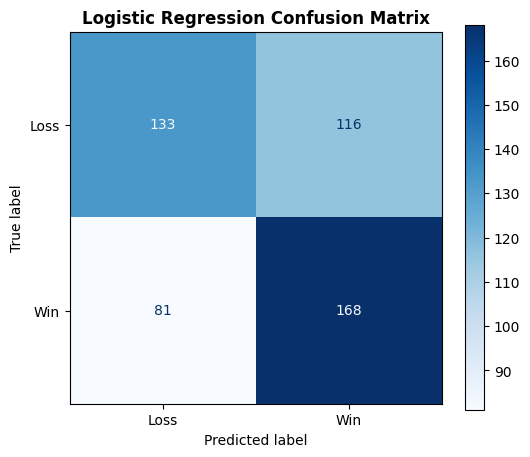

In [147]:
# Logistic Regression confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm_display1 = metrics.ConfusionMatrixDisplay(confusion_matrix = conf_matrix1, display_labels=['Loss', 'Win'])

cm_display1.plot(cmap='Blues', ax=ax)
ax.set_title("Logistic Regression Confusion Matrix", fontsize=12, fontweight="bold")
plt.show()

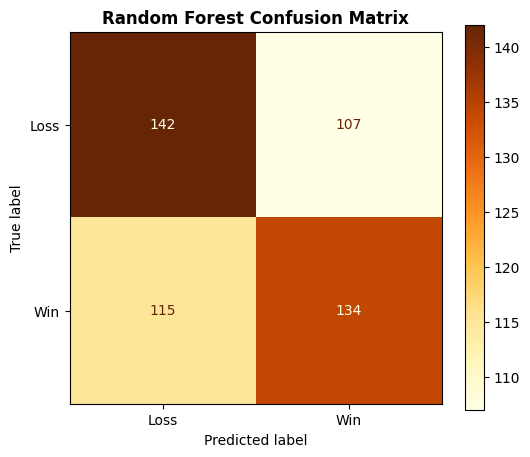

In [148]:
# Random Forest Confusion Matrix Plot
fig, ax = plt.subplots(figsize=(6, 5))
cm_display2 = metrics.ConfusionMatrixDisplay(confusion_matrix = conf_matrix2, display_labels=['Loss', 'Win'])

cm_display2.plot(cmap="YlOrBr", ax=ax)
ax.set_title("Random Forest Confusion Matrix", fontsize=12, fontweight="bold")
plt.show()

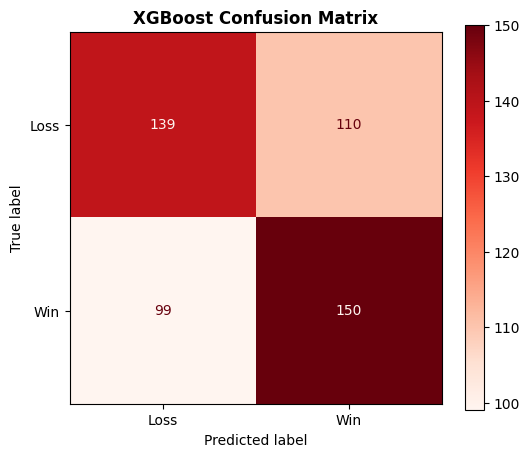

In [149]:
# XGBoost Confusion Matrix Plot
fig, ax = plt.subplots(figsize=(6, 5))
cm_display3 = metrics.ConfusionMatrixDisplay(confusion_matrix = conf_matrix3, display_labels=['Loss', 'Win'])

cm_display3.plot(cmap="Reds", ax=ax)
ax.set_title("XGBoost Confusion Matrix", fontsize=12, fontweight="bold")
plt.show()

#### Observation:

- The logistic regression correctly predicted the true positive and true negatives with a total of 376 correct predictions.
- 181 False Positives and 171 False Negatives which is still a bit high because this time we're predicting the outcomes of an upcoming game based on the last 5 games (before, we didn't based on this so we predict the outcome of the game based on the outcome stats which makes it easer for models to predict more accurately) 
- While the random forest classifier has slightly fewer correct predictions with a total of 364 identified true positives and true negaticves. 
- 161 False Positives which is a bit lower than logisitc regression but it 203 False Negatives which shows less accuracy of this model.